# Evaluator: Organic Experiential Learning (NK + SARSA)

This notebook evaluates `Organic_experiential_learning.py` with **no AI assistance**. The focal parameter is **cumulative learning steps** (SARSA updates). The main figures show subsequent evaluation performance and internal-knowledge outcomes, averaged over NK complexity or plotted separately for each $K$.

**Inputs:** `organic_learning_raw.csv`, `organic_learning_summary.csv`, and `organic_learning_evaluation_trajectories_K_*.pkl`. The evaluator does **not** rerun simulations or change either `Landscape.py` or `Individual.py`. It saves high-resolution transparent **PNG figures only**.

**Interpretation:** Training accumulates knowledge; evaluation uses a more exploitative policy without updating the Q-table. Performance outcomes concern *fixed-budget evaluation search*, not time-to-goal or the final training state.

*Preview note:* The saved example figures were generated from a **small smoke-test run** ($N=4$, $K=0,2$, four learners per condition) to validate the evaluator, **not** the full baseline experiment. Re-execute after pointing `result_folder` to your own results.

## 1. Configuration and figure style

Figure formatting follows the supplied visibility-extent evaluator: bold axis labels, black outlined markers for pooled plots, Morandi colors by $K$, moderate grids, strong black spines, and PNG export at 300 dpi.

Learning budgets may span orders of magnitude; a **symmetric logarithmic** learning-step axis retains the zero-learning condition while separating larger budgets. Set `learning_axis = 'linear'` to use actual linear spacing.

**Edit `result_folder`** if the notebook cannot find the directory produced by the baseline running script. `strict_loading=True` requires complete $(K,\mathrm{learning\ steps})$ combinations.

In [1]:
from pathlib import Path
import os
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Same palette and styling as the supplied Evaluator.ipynb.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91']


def format_axis(ax):
    """Match the original evaluator's figure formatting."""
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.5)
    ax.tick_params(axis='both', labelsize=11)
    return ax


def format_learning_axis(ax):
    """Show the actual SARSA update counts, including zero."""
    if learning_axis == 'symlog':
        positives = [step for step in learning_steps_list if step > 0]
        linthresh = min(positives) if positives else 1
        ax.set_xscale('symlog', linthresh=linthresh)
    elif learning_axis != 'linear':
        raise ValueError("learning_axis must be 'symlog' or 'linear'.")
    ax.set_xticks(learning_steps_list)
    ax.set_xticklabels([f'{step:,}' for step in learning_steps_list],
                       rotation=25 if len(learning_steps_list) > 6 else 0,
                       ha='right' if len(learning_steps_list) > 6 else 'center')
    ax.set_xlabel('Cumulative learning steps', fontweight='bold', fontsize=12)
    return ax


def finish_figure(fig, filename):
    fig.tight_layout()
    if save_figures:
        fig.savefig(figure_folder / filename, dpi=300,
                    bbox_inches='tight', transparent=True)
    plt.show()

In [2]:
# =========================
# Experiment configuration — Organic_experiential_learning.py
# =========================
# None searches common locations; alternatively set a local directory explicitly.
# For execution in a different working folder, set ORGANIC_RESULTS_DIR.
result_folder = os.environ.get('ORGANIC_RESULTS_DIR')  # e.g., '/Volumes/T7/data/Organic_experiential_learning_results'

save_figures = True
strict_loading = True             # False allows inspection of partial K / budget results.
learning_axis = 'symlog'         # 'symlog' (default) or 'linear'.

candidate_folders = [Path.cwd() / 'Organic_experiential_learning_results',
                     Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']

if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / 'organic_learning_summary.csv').is_file()), None)
if result_folder is None:
    raise FileNotFoundError(
        'Could not locate organic_learning_summary.csv. Set result_folder to '
        'the output_dir in Organic_experiential_learning.py, or set ORGANIC_RESULTS_DIR.')

result_folder = Path(result_folder).expanduser().resolve()
summary_file = result_folder / 'organic_learning_summary.csv'
raw_file = result_folder / 'organic_learning_raw.csv'
if not summary_file.is_file():
    raise FileNotFoundError(f'Missing summary CSV: {summary_file}')

figure_folder = result_folder / 'organic_learning_figures'
if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)

print('Result folder:', result_folder)
print('Figure folder:', figure_folder)
print('Save PNG figures:', save_figures)

Result folder: /mnt/data/_organic_baseline_smoketest_again
Figure folder: /mnt/data/_organic_baseline_smoketest_again/organic_learning_figures
Save PNG figures: True


## 2. Load and validate experiment outputs

The summary CSV contains **one row per $(K,\mathrm{learning\ steps})$ configuration**. Each mean was calculated from individual runs (multiple independently drawn landscapes and learner resets). The raw CSV retains those observations for later statistical analysis.

The notebook dynamically reads $N$, the sampled $K$ values, and learning budgets from the output. No hardcoded experiment grid is necessary. Main figures **average the $K$-specific means equally**, replicating the pooling convention in your previous evaluator.

In [3]:
summary = pd.read_csv(summary_file)
raw = pd.read_csv(raw_file) if raw_file.is_file() else None

required = ['N', 'K', 'learning_steps', 'n_individual_runs',
            'evaluation_best_fitness_mean', 'evaluation_best_rank_mean',
            'state_coverage_mean', 'action_coverage_mean']
missing_columns = [column for column in required if column not in summary.columns]
if missing_columns:
    raise ValueError(f'Missing expected summary columns: {missing_columns}')
if summary.duplicated(['K', 'learning_steps']).any():
    raise ValueError('Duplicate (K, learning_steps) configurations in summary CSV.')

N_values = sorted(summary['N'].dropna().unique().astype(int).tolist())
if len(N_values) != 1:
    raise ValueError(f'Expected one N in a result directory; found {N_values}.')
N = N_values[0]
K_list = sorted(summary['K'].dropna().unique().astype(int).tolist())
learning_steps_list = sorted(summary['learning_steps'].dropna().unique().astype(int).tolist())
summary = summary.sort_values(['K', 'learning_steps']).reset_index(drop=True)

expected = pd.MultiIndex.from_product([K_list, learning_steps_list],
                                      names=['K', 'learning_steps'])
actual = pd.MultiIndex.from_frame(summary[['K', 'learning_steps']])
missing_combinations = expected.difference(actual)
if len(missing_combinations):
    print('Missing (K, learning_steps) configurations:', missing_combinations.tolist())
    if strict_loading:
        raise ValueError('Incomplete experiment summary. Set strict_loading=False to inspect partial results.')

measure_names = [column[:-5] for column in summary.columns if column.endswith('_mean')]
data = {
    measure: summary.pivot(index='learning_steps', columns='K',
                           values=measure + '_mean').reindex(
                               index=learning_steps_list, columns=K_list)
    for measure in measure_names
}

print(f'N={N}; K={K_list}; learning checkpoints={learning_steps_list}')
print('Summary configurations:', len(summary), '| expected:', len(expected))
print('Individual runs per configuration:',
      sorted(summary['n_individual_runs'].dropna().unique().astype(int).tolist()))
print('Raw observations:', len(raw) if raw is not None else 'not available')

display(summary[['K', 'learning_steps', 'n_individual_runs',
                 'evaluation_best_fitness_mean', 'evaluation_best_rank_mean',
                 'state_coverage_mean', 'action_coverage_mean']].head(12))

N=4; K=[0, 2]; learning checkpoints=[0, 3, 8]
Summary configurations: 6 | expected: 6
Individual runs per configuration: [4]
Raw observations: 24


,K,learning_steps,n_individual_runs,evaluation_best_fitness_mean,evaluation_best_rank_mean,state_coverage_mean,action_coverage_mean
0,0,0,4,0.769166,3.625,0.000000,0.000000
1,0,3,4,0.777365,3.500,0.187500,0.046875
2,0,8,4,0.710877,5.000,0.359375,0.117188
3,2,0,4,0.762190,3.750,0.000000,0.000000
4,2,3,4,0.726352,4.000,0.171875,0.046875
5,2,8,4,0.799202,3.000,0.390625,0.121094


In [4]:
# =========================
# Data integrity checks
# =========================
checks = {
    'evaluation_best_fitness': (0, 1),
    'evaluation_final_fitness': (0, 1),
    'evaluation_best_rank': (1, 2 ** N),
    'state_coverage': (0, 1),
    'action_coverage': (0, 1),
    'informed_percentage': (0, 1),
}
for measure, (minimum, maximum) in checks.items():
    if measure not in data:
        continue
    values = data[measure].to_numpy(dtype=float)
    finite = values[np.isfinite(values)]
    outside = np.count_nonzero((finite < minimum - 1e-8) |
                               (finite > maximum + 1e-8))
    print(f'{measure:29s} finite={finite.size:3d} / {values.size:3d}; '
          f'outside expected range={outside}')
    if outside:
        warnings.warn(f'{measure} contains values outside expected range.')

if raw is not None:
    keys = ['N', 'K', 'landscape_repetition', 'individual_reset', 'learning_steps']
    if not set(keys).issubset(raw.columns):
        warnings.warn('Raw CSV lacks identifiers needed for duplicate checks.')
    else:
        duplicates = int(raw.duplicated(keys).sum())
        print('Duplicate raw experiment identifiers:', duplicates)
        if duplicates:
            raise ValueError('Duplicate raw observations found.')

    # Recompute the saved mean from the underlying run-level observations.
    for measure in ['evaluation_best_fitness', 'state_coverage', 'action_coverage']:
        if measure in raw and measure + '_mean' in summary:
            observed = raw.groupby(['K', 'learning_steps'])[measure].mean()
            expected_means = summary.set_index(['K', 'learning_steps'])[measure + '_mean']
            comparable = observed.index.intersection(expected_means.index)
            difference = np.abs(observed.loc[comparable] - expected_means.loc[comparable])
            print(f'Max raw-to-summary discrepancy ({measure}):',
                  float(difference.max()) if len(difference) else np.nan)
            if len(difference) and difference.max() > 1e-8:
                warnings.warn(f'Raw and summary {measure} means do not match.')

print('Note: evaluation_best_rank is the mean rank of best-discovered states, '
      'not the rank of mean fitness.')

evaluation_best_fitness       finite=  6 /   6; outside expected range=0
evaluation_final_fitness      finite=  6 /   6; outside expected range=0
evaluation_best_rank          finite=  6 /   6; outside expected range=0
state_coverage                finite=  6 /   6; outside expected range=0
action_coverage               finite=  6 /   6; outside expected range=0
informed_percentage           finite=  6 /   6; outside expected range=0
Duplicate raw experiment identifiers: 0
Max raw-to-summary discrepancy (evaluation_best_fitness): 0.0
Max raw-to-summary discrepancy (state_coverage): 0.0
Max raw-to-summary discrepancy (action_coverage): 0.0
Note: evaluation_best_rank is the mean rank of best-discovered states, not the rank of mean fitness.


## 3. Main performance outcomes

- **Evaluation best fitness:** highest NK fitness reached during a fixed-length evaluation search, averaged over the independent test starts.
- **Evaluation best rank:** rank of each evaluation trajectory's best-discovered state (rank 1 is optimal). The figure reverses the vertical axis so that better outcomes appear higher.
- **Evaluation final fitness** and **fitness gain** are supplementary and should not be conflated with best-discovered fitness.

Training and evaluation use distinct temperatures, and *evaluation does not update internal Q-values*.

In [5]:
# Utilities: pooled-over-K and per-K figures match the earlier evaluator.
def plot_pooled(measure, ylabel, filename, invert=False, bounds=None):
    if measure not in data:
        print('Unavailable measure:', measure)
        return
    values = data[measure].mean(axis=1, skipna=True).to_numpy(dtype=float)
    if not np.isfinite(values).any():
        print(f'{measure} unavailable (all NaN); figure skipped.')
        return
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    ax.plot(learning_steps_list, values, marker='o', linewidth=2.5,
            markersize=7, color='k', markerfacecolor='white',
            markeredgecolor='black', markeredgewidth=1.5)
    format_learning_axis(ax)
    ax.set_ylabel(ylabel, fontweight='bold', fontsize=12)
    if invert:
        ax.invert_yaxis()
    if bounds is not None:
        ax.set_ylim(*bounds)
    finish_figure(fig, filename)


def plot_by_K(measure, ylabel, filename, invert=False, bounds=None):
    if measure not in data or not np.isfinite(data[measure].to_numpy()).any():
        print(f'{measure} unavailable (all NaN); figure skipped.')
        return
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    for j, K in enumerate(K_list):
        ax.plot(learning_steps_list, data[measure][K].to_numpy(dtype=float),
                marker='o', linewidth=2.0, markersize=4.5,
                label=f'K={K}', color=K_colors[j % len(K_colors)])
    format_learning_axis(ax)
    ax.set_ylabel(ylabel, fontweight='bold', fontsize=12)
    if invert:
        ax.invert_yaxis()
    if bounds is not None:
        ax.set_ylim(*bounds)
    ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
    finish_figure(fig, filename)

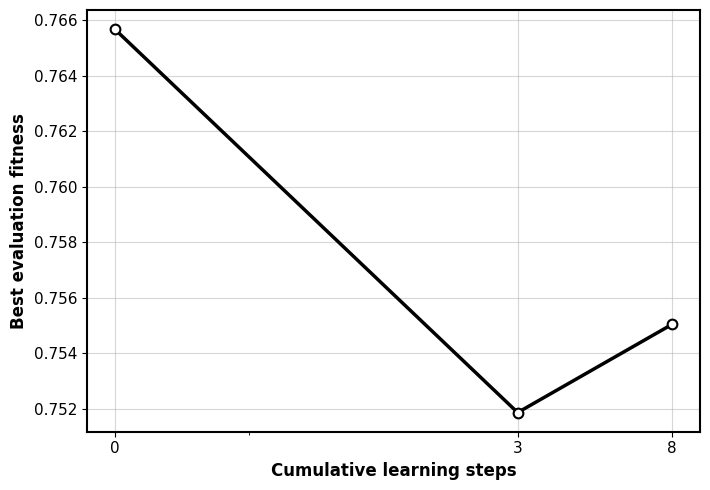

In [6]:
# Best-discovered evaluation fitness vs. experiential learning (average across K).
plot_pooled('evaluation_best_fitness', 'Best evaluation fitness',
            'Evaluation_best_fitness_across_learning_steps.png')

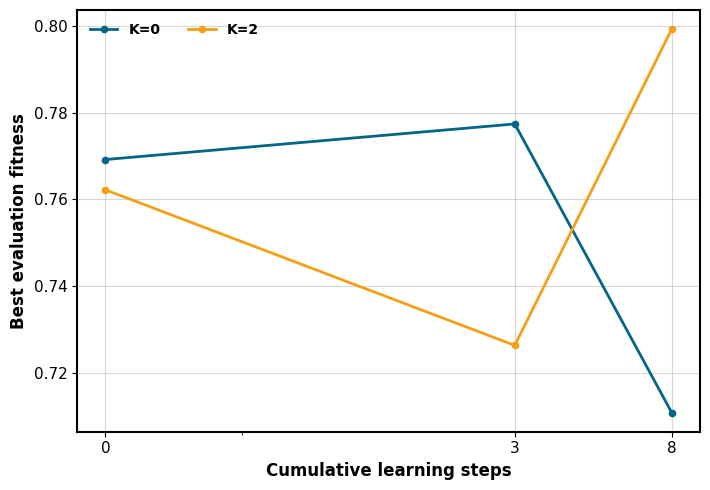

In [7]:
# Best-discovered evaluation fitness vs. experiential learning (by K).
plot_by_K('evaluation_best_fitness', 'Best evaluation fitness',
          'Evaluation_best_fitness_by_K_across_learning_steps.png')

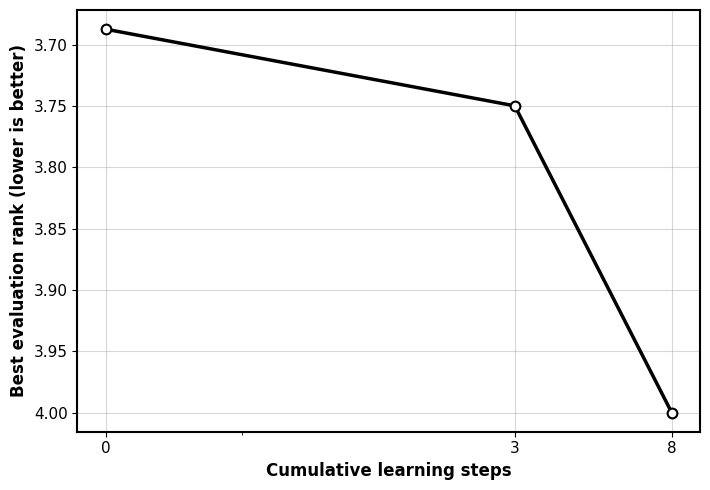

In [8]:
# Best-discovered solution rank (average across K; rank 1 is better).
plot_pooled('evaluation_best_rank', 'Best evaluation rank (lower is better)',
            'Evaluation_best_rank_across_learning_steps.png', invert=True)

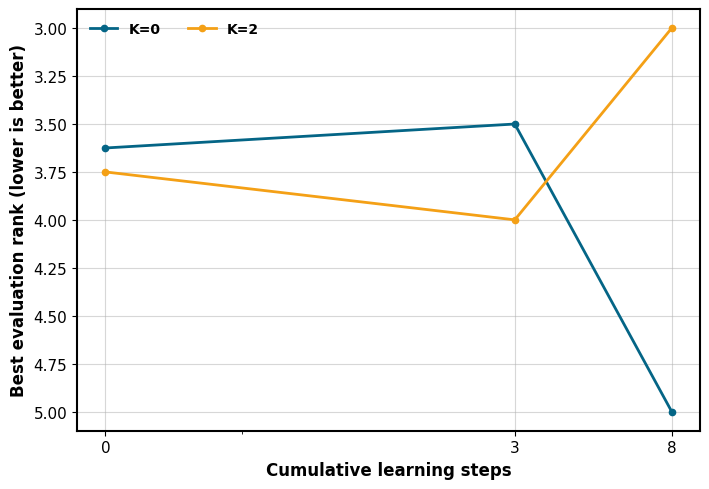

In [9]:
# Best-discovered solution rank (by K).
plot_by_K('evaluation_best_rank', 'Best evaluation rank (lower is better)',
          'Evaluation_best_rank_by_K_across_learning_steps.png', invert=True)

## 4. Internal knowledge: coverage and informativeness

Coverage is the share of the entire $2^N	imes N$ decision space with at least one update. Both measures are *descriptive knowledge-acquisition outcomes*, not direct measures of correctness.

- **State coverage:** fraction of states with at least one SARSA-updated action.
- **Action coverage:** fraction of all state–action pairs updated.
- **Informed percentage:** fraction of states with at least one nonzero Q-value (may differ from state coverage when an update remains zero).

In a large NK state space, coverage can remain low even after many learning steps.

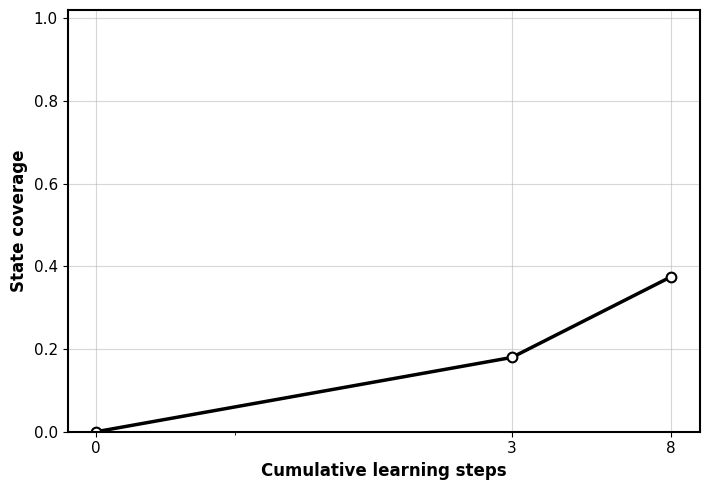

In [10]:
# Breadth of experiential learning (average across K).
plot_pooled('state_coverage', 'State coverage',
            'State_coverage_across_learning_steps.png', bounds=(0, 1.02))

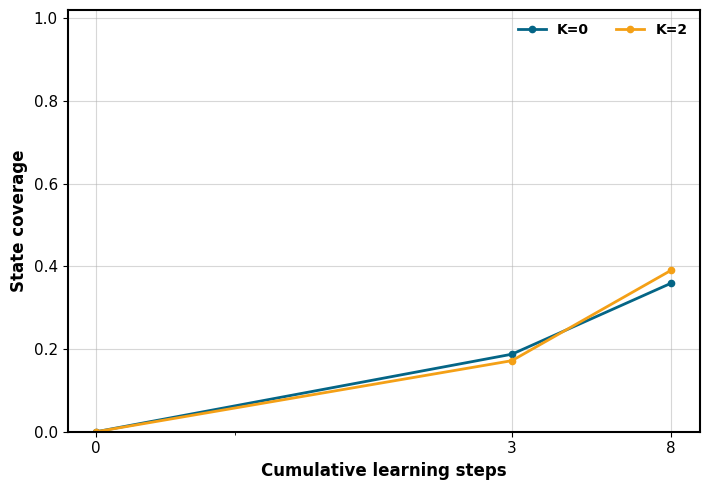

In [11]:
# Breadth of experiential learning (by K).
plot_by_K('state_coverage', 'State coverage',
          'State_coverage_by_K_across_learning_steps.png', bounds=(0, 1.02))

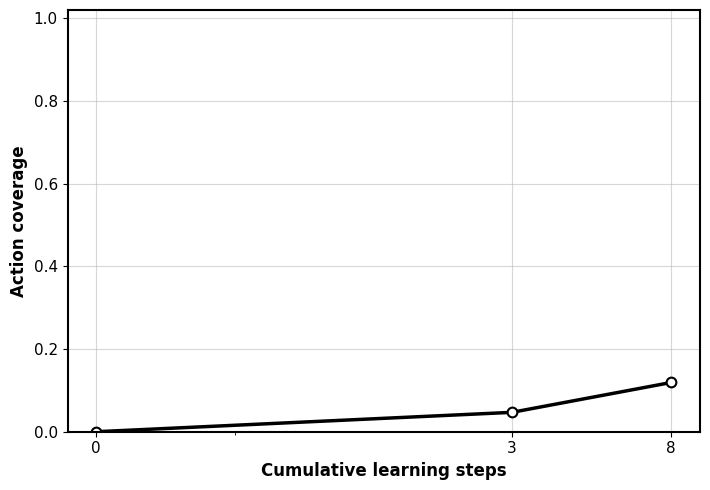

In [12]:
# Coverage of updated state-action pairs (average across K).
plot_pooled('action_coverage', 'Action coverage',
            'Action_coverage_across_learning_steps.png', bounds=(0, 1.02))

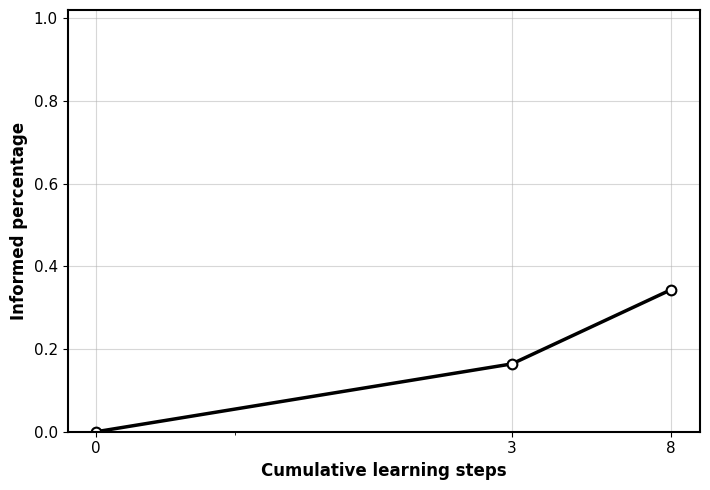

In [13]:
# Nonzero Q-value state coverage, retaining the original informativeness idea.
plot_pooled('informed_percentage', 'Informed percentage',
            'Informed_percentage_across_learning_steps.png', bounds=(0, 1.02))

## 5. Internal knowledge: Q-value accuracy

These measures are only available if `compute_accuracy=True` was used in the simulation. Missing (`NaN`) values are **not** treated as zero.

- **Overall Q accuracy:** one minus normalized RMSE of learned $Q(s,a)$ against the **exact on-policy** $Q^\pi(s,a)$ over all pairs.
- **Experienced Q accuracy:** the same comparison restricted to pairs with at least one update; this metric is **undefined** at zero learning steps.

**Caveat:** the reference $Q^\pi$ changes with the individual's current softmax policy, so accuracy is not evaluated against one invariant target. Experienced accuracy also has a changing denominator as more pairs are visited. These outcomes should be interpreted alongside coverage, not as independent ground-truth knowledge tests.

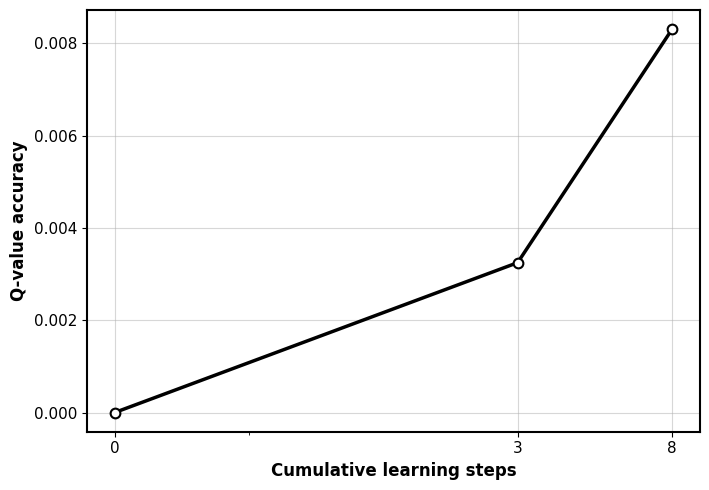

In [14]:
# Overall accuracy of the Q-table relative to the learner's current policy.
plot_pooled('q_accuracy', 'Q-value accuracy',
            'Q_accuracy_across_learning_steps.png')

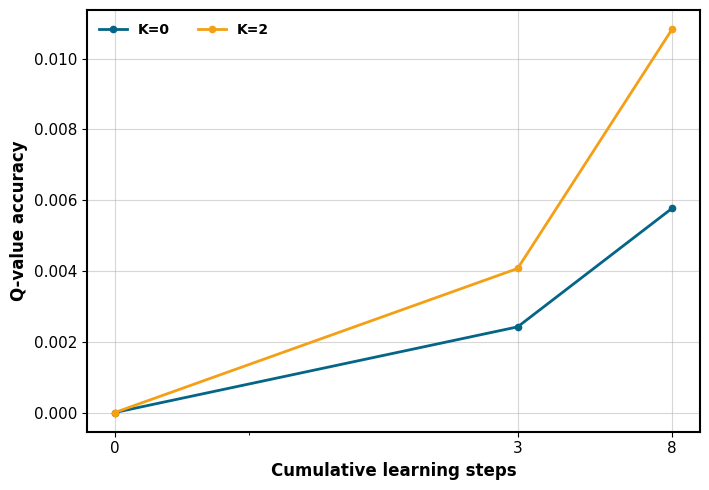

In [15]:
# Q-value accuracy separately by task interdependence.
plot_by_K('q_accuracy', 'Q-value accuracy',
          'Q_accuracy_by_K_across_learning_steps.png')

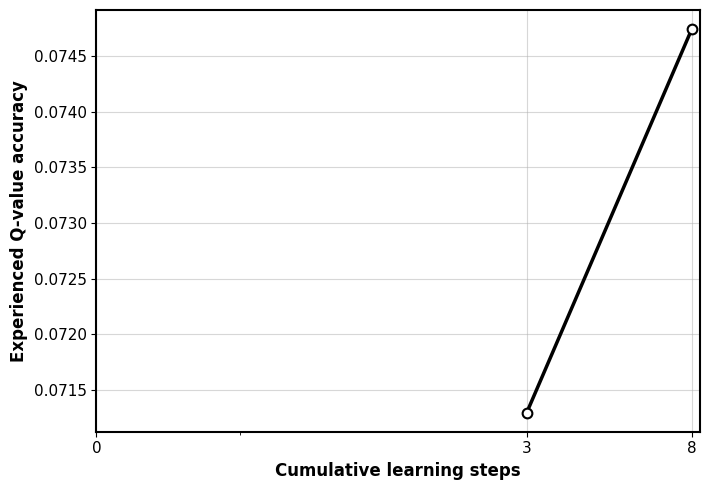

In [16]:
# Conditional Q-value accuracy among the state-action pairs actually learned.
plot_pooled('experienced_q_accuracy', 'Experienced Q-value accuracy',
            'Experienced_Q_accuracy_across_learning_steps.png')

## 6. Supplementary performance measures

Unlike the best-discovered metric, **final fitness** is the fitness at the final evaluation step; it can be lower if the individual moves away from a promising solution. **Evaluation fitness gain** equals best fitness minus starting fitness on the *same* evaluation trajectory. Results are descriptive across learning checkpoints and NK complexity.

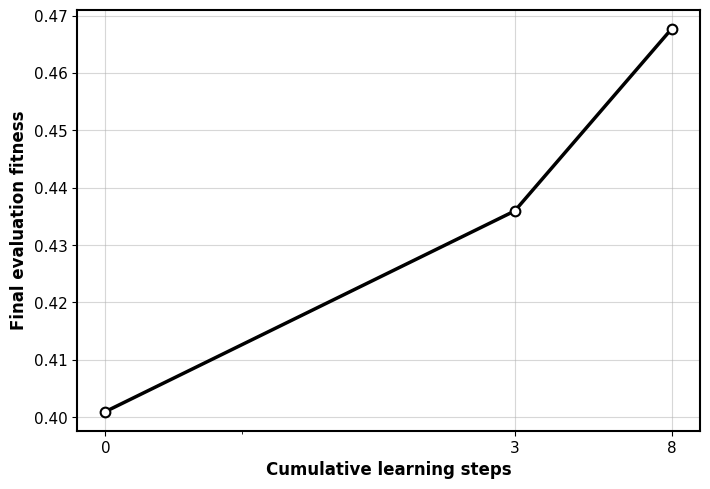

In [17]:
# Evaluation final-position fitness (average across K).
plot_pooled('evaluation_final_fitness', 'Final evaluation fitness',
            'Evaluation_final_fitness_across_learning_steps.png')

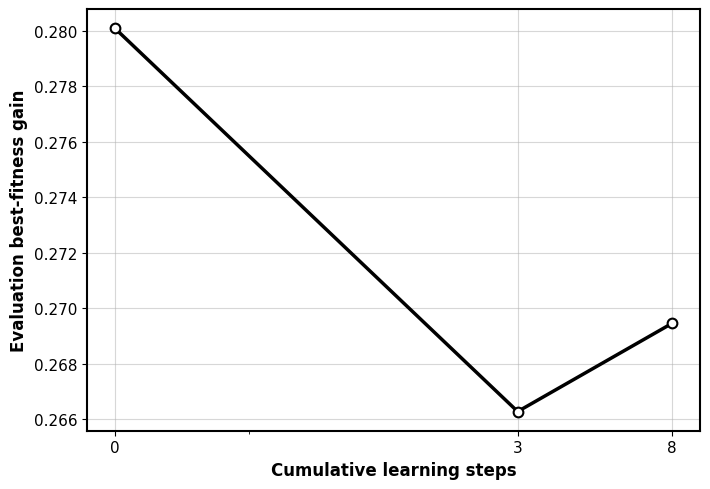

In [18]:
# Best-fitness gain relative to evaluation starts (average across K).
plot_pooled('evaluation_fitness_gain', 'Evaluation best-fitness gain',
            'Evaluation_fitness_gain_across_learning_steps.png')

## 7. Evaluation search trajectories

For each $K$, `organic_learning_evaluation_trajectories_K_*.pkl` stores a dictionary mapping **learning checkpoints** to mean *best-fitness-so-far* evaluation trajectories. Each trajectory has `evaluation_search_steps + 1` entries, including the initial state at evaluation step 0. The trajectories are averaged across learners and independent evaluation starts within each $K$.

The figures compare selected learning budgets for one $K$ and then hold the learning budget fixed to compare $K$. Missing pickle files are reported explicitly and skipped, rather than interpreted as zero.

In [19]:
# =========================
# Load evaluation best-fitness trajectories
# =========================
trajectories = {}
missing_trajectories = []
for K in K_list:
    path = result_folder / f'organic_learning_evaluation_trajectories_K_{K}.pkl'
    if not path.is_file():
        missing_trajectories.append(path.name)
        continue
    with open(path, 'rb') as infile:
        saved = pickle.load(infile)
    if not isinstance(saved, dict):
        raise TypeError(f'Trajectory file must contain a dictionary: {path.name}')
    trajectories[K] = {int(step): np.asarray(series, dtype=float)
                       for step, series in saved.items()}
    lengths = {len(series) for series in trajectories[K].values()}
    if len(lengths) != 1:
        raise ValueError(f'Unequal trajectory lengths within K={K}: {lengths}')

print('Loaded trajectory files:', len(trajectories), '/', len(K_list))
if missing_trajectories:
    print('Missing:', missing_trajectories)

# Optional verification: the last mean best-fitness trajectory value should
# equal the corresponding summary scalar, within rounding error.
maximum_gap = 0.0
for K, by_budget in trajectories.items():
    for step, series in by_budget.items():
        if step in data['evaluation_best_fitness'].index:
            scalar = data['evaluation_best_fitness'].loc[step, K]
            if np.isfinite(scalar) and len(series):
                maximum_gap = max(maximum_gap, abs(float(series[-1]) - float(scalar)))
print('Max trajectory endpoint vs. summary fitness discrepancy:', maximum_gap)
if maximum_gap > 1e-8:
    warnings.warn('Evaluation trajectories do not match summary best-fitness values.')

Loaded trajectory files: 2 / 2
Max trajectory endpoint vs. summary fitness discrepancy: 0.0


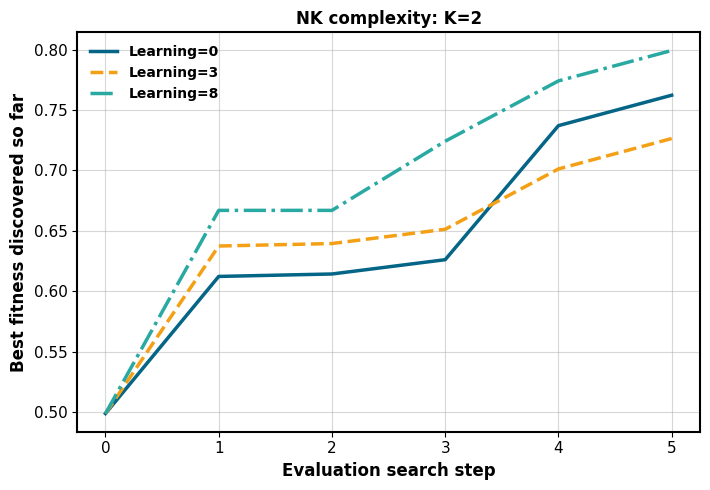

In [20]:
# Search process: three learning budgets on one selected NK complexity.
trajectory_K = K_list[len(K_list) // 2]  # Change to another observed K if desired.
selected_indices = [0, len(learning_steps_list) // 2, len(learning_steps_list) - 1]
trajectory_learning_steps = list(dict.fromkeys(
    learning_steps_list[index] for index in selected_indices))

if trajectory_K not in trajectories:
    print(f'No trajectory file for K={trajectory_K}.')
else:
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    for j, budget in enumerate(trajectory_learning_steps):
        if budget not in trajectories[trajectory_K]:
            print(f'No trajectory for K={trajectory_K}, learning_steps={budget}')
            continue
        series = trajectories[trajectory_K][budget]
        ax.plot(np.arange(len(series)), series, linewidth=2.5,
                linestyle=['-', '--', '-.'][j % 3],
                color=[morandi_blue, morandi_orange, morandi_green][j % 3],
                label=f'Learning={budget:,}')
    ax.set_xlabel('Evaluation search step', fontweight='bold', fontsize=12)
    ax.set_ylabel('Best fitness discovered so far', fontweight='bold', fontsize=12)
    ax.legend(frameon=False, prop={'weight': 'bold', 'size': 10})
    ax.set_title(f'NK complexity: K={trajectory_K}', fontweight='bold', fontsize=12)
    finish_figure(fig, f'Evaluation_trajectories_by_learning_budget_K_{trajectory_K}.png')

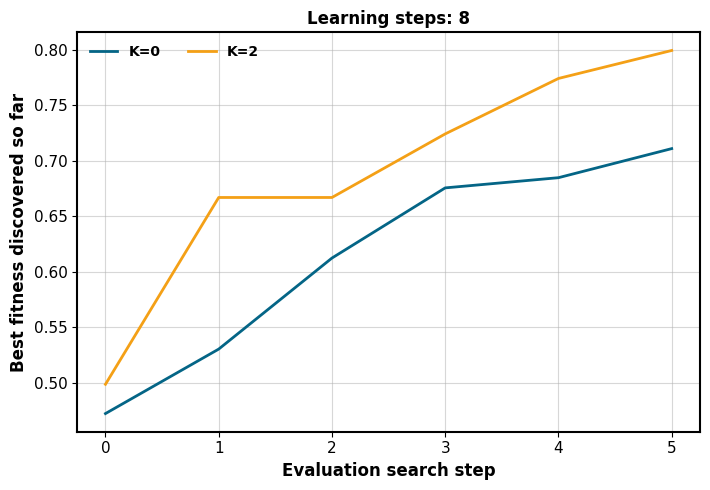

In [21]:
# Search process: compare K at the same (last) learning checkpoint.
trajectory_learning_budget = learning_steps_list[-1]
if not trajectories:
    print('No trajectory data available.')
else:
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    plotted = 0
    for j, K in enumerate(K_list):
        if K not in trajectories or trajectory_learning_budget not in trajectories[K]:
            continue
        series = trajectories[K][trajectory_learning_budget]
        ax.plot(np.arange(len(series)), series, linewidth=2.0,
                color=K_colors[j % len(K_colors)], label=f'K={K}')
        plotted += 1
    ax.set_xlabel('Evaluation search step', fontweight='bold', fontsize=12)
    ax.set_ylabel('Best fitness discovered so far', fontweight='bold', fontsize=12)
    ax.set_title(f'Learning steps: {trajectory_learning_budget:,}',
                 fontweight='bold', fontsize=12)
    if plotted:
        ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
        finish_figure(fig, f'Evaluation_trajectories_by_K_learning_{trajectory_learning_budget}.png')
    else:
        plt.close(fig)
        print('No matching checkpoint in any trajectory file.')

## 8. Learning × NK complexity: diagnostic heatmaps

Heatmaps display the underlying saved **$(K, \mathrm{learning\ steps})$ means** without pooling over complexity. These are diagnostics for heterogeneous effects, not statistical tests. Missing conditions remain blank.

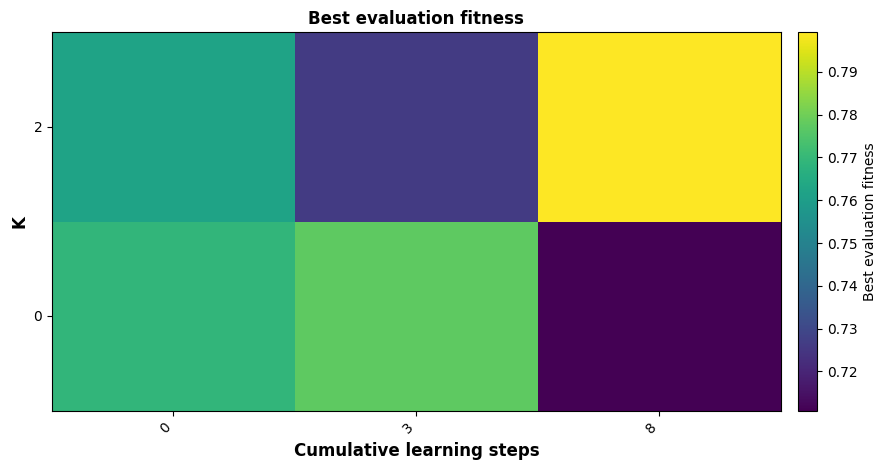

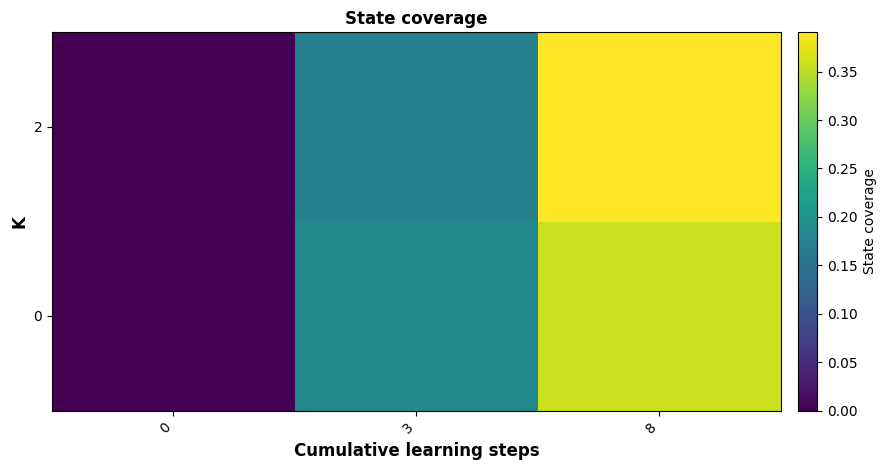

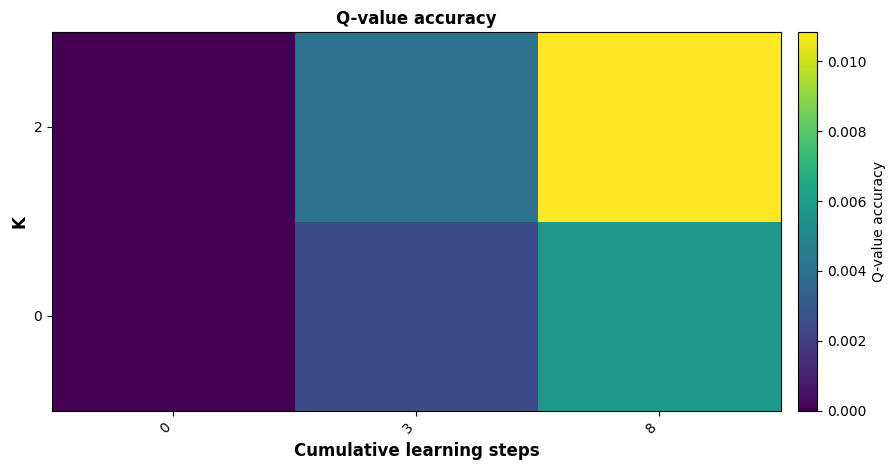

In [22]:
for measure, title, filename, cmap in [
    ('evaluation_best_fitness', 'Best evaluation fitness',
     'Evaluation_best_fitness_heatmap_learning_by_K.png', 'viridis'),
    ('state_coverage', 'State coverage',
     'State_coverage_heatmap_learning_by_K.png', 'viridis'),
    ('q_accuracy', 'Q-value accuracy',
     'Q_accuracy_heatmap_learning_by_K.png', 'viridis'),
]:
    if measure not in data or not np.isfinite(data[measure].to_numpy()).any():
        print(f'{measure} unavailable; heatmap skipped.')
        continue
    values = np.ma.masked_invalid(data[measure].T.to_numpy(dtype=float))
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    image = ax.imshow(values, aspect='auto', interpolation='nearest',
                      cmap=cmap, origin='lower')
    ax.set_xticks(np.arange(len(learning_steps_list)))
    ax.set_xticklabels([f'{step:,}' for step in learning_steps_list],
                       rotation=45, ha='right')
    ax.set_yticks(np.arange(len(K_list)))
    ax.set_yticklabels(K_list)
    ax.set_xlabel('Cumulative learning steps', fontweight='bold', fontsize=12)
    ax.set_ylabel('K', fontweight='bold', fontsize=12)
    ax.set_title(title, fontweight='bold', fontsize=12)
    fig.colorbar(image, ax=ax, label=title, pad=0.02)
    finish_figure(fig, filename)

## 9. Takeaways and interpretation

Use the main performance curves to assess **whether additional experiential learning improves fixed-budget solution discovery**, and the coverage/accuracy figures to assess **how internal knowledge changes**. The latter measures are proposed mechanisms, not evidence of mediation by themselves.

**Design cautions:** Each checkpoint reuses the *same learner* and test starting states. Landscape and individual resets are nested, so repeated checkpoints and evaluation resets should not be treated as independent observations in subsequent regressions. Equal-weighted averages across $K$ are descriptive. With few smoke-test repetitions, plotted fluctuations must not be interpreted as empirical patterns. In particular, high SARSA reward estimates can encourage revisiting good states rather than maximizing the single best state encountered.

In [23]:
# Compact report of available end-to-end comparisons (descriptive only).
comparison_measures = ['evaluation_best_fitness', 'evaluation_best_rank',
                       'state_coverage', 'action_coverage',
                       'q_accuracy', 'experienced_q_accuracy']
first_budget, last_budget = learning_steps_list[0], learning_steps_list[-1]
rows = []
for measure in comparison_measures:
    if measure not in data:
        continue
    pooled = data[measure].mean(axis=1, skipna=True)
    first, last = pooled.loc[first_budget], pooled.loc[last_budget]
    rows.append({'Measure': measure,
                 f'{first_budget:,} learning steps': first,
                 f'{last_budget:,} learning steps': last,
                 'Difference (last - first)': (last - first) if np.isfinite(first) and np.isfinite(last) else np.nan})
display(pd.DataFrame(rows).round(4))
print('All plots above summarize the loaded simulation outputs; no AI condition is included.')

,Measure,0 learning steps,8 learning steps,Difference (last - first)
0,evaluation_best_fitness,0.7657,0.7550,-0.0106
1,evaluation_best_rank,3.6875,4.0000,0.3125
2,state_coverage,0.0000,0.3750,0.3750
3,action_coverage,0.0000,0.1191,0.1191
4,q_accuracy,0.0000,0.0083,0.0083
5,experienced_q_accuracy,NaN,0.0747,NaN


All plots above summarize the loaded simulation outputs; no AI condition is included.
